# Klasifikasi Kondisi Air: EDA dan Model

Dataset ini hasil rekaman ESP32 tanggal 3 Nov 2026, diexport dari dashboard.
Satu baris = satu pembacaan sensor (tiap 3 detik). Data waktu pompa nyala udah dibuang otomatis waktu export.

Label diset dari dashboard waktu ngerekam tiap jenis air:

| Label | Airnya |
|---|---|
| `clear` | air keran bersih |
| `slightly_turbid` | air bersih + garam + sedikit susu |
| `dirty` | garam dan susunya ditambah lagi |

Tujuannya: tebak label dari nilai sensor, bandingin beberapa model, terus pilih yang cukup kecil buat jalan di ESP32.

Isi notebook:
1. Load data
2. Lihat data
3. Cleaning
4. EDA
5. Pilih fitur
6. Split train/test
7. Training dan perbandingan model
8. Evaluasi
9. Model mana yang muat di ESP32
10. Simpan model

## 1. Load data

In [1]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

LABELS = ["clear", "slightly_turbid", "dirty"]
COLORS = {"clear": "#2a9d8f", "slightly_turbid": "#e9c46a", "dirty": "#a0522d"}

raw = pd.read_csv("data/iot_project_dataset_2026-11-04.csv")
raw["timestamp_wib"] = pd.to_datetime(raw["timestamp_wib"])
print("Jumlah baris:", len(raw), "| kolom:", raw.shape[1])
raw.head()

Jumlah baris: 1022 | kolom: 7


,timestamp_wib,t_tank,tds,tds_v,turb,turb_v,label
0,2026-11-03 19:44:46,21.44,277.5,0.696,9.1,1.700,clear
1,2026-11-03 19:44:49,21.44,277.5,0.696,9.3,1.699,clear
2,2026-11-03 19:44:52,21.44,277.5,0.696,9.1,1.700,clear
3,2026-11-03 19:44:55,21.44,277.4,0.696,9.5,1.698,clear
4,2026-11-03 19:44:59,21.44,277.5,0.696,9.5,1.698,clear


Arti kolomnya:

| Kolom | Isi |
|---|---|
| `timestamp_wib` | waktu pembacaan (WIB) |
| `t_tank` | suhu air dari DS18B20 (°C) |
| `tds`, `tds_v` | TDS dalam ppm (udah dikompensasi suhu) dan tegangan mentahnya |
| `turb`, `turb_v` | indeks kekeruhan 0-100 dan tegangan mentah sensor (makin tinggi V = makin jernih) |
| `label` | kondisi air yang diset di dashboard (target) |

Kolom float switch, skor, pompa, dan mode nggak ikut di dataset karena itu kondisi alat, bukan kondisi air.

## 2. Lihat data

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1022 entries, 0 to 1021
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp_wib  1022 non-null   datetime64[ns]
 1   t_tank         1022 non-null   float64       
 2   tds            1022 non-null   float64       
 3   tds_v          1022 non-null   float64       
 4   turb           1022 non-null   float64       
 5   turb_v         1022 non-null   float64       
 6   label          1022 non-null   object        
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 56.0+ KB


In [3]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp_wib,1022,2026-11-03 20:10:30.792563712,2026-11-03 19:44:46,2026-11-03 19:57:36.750000128,2026-11-03 20:10:29.500000,2026-11-03 20:23:24.249999872,2026-11-03 20:36:20,NaN
t_tank,1022.0,22.185,21.38,21.56,22.5,22.56,22.63,0.476
tds,1022.0,546.547,260.3,277.0,357.8,969.1,981.6,314.167
tds_v,1022.0,1.233,0.652,0.695,0.927,2.013,2.027,0.584
turb,1022.0,35.161,0.0,8.5,36.8,59.6,83.1,25.094
turb_v,1022.0,1.557,1.293,1.422,1.547,1.703,1.764,0.138


In [4]:
print("Missing value per kolom:")
print(raw.isna().sum())
print()
print("Jumlah baris per label:")
print(raw["label"].value_counts(dropna=False))

Missing value per kolom:
timestamp_wib    0
t_tank           0
tds              0
tds_v            0
turb             0
turb_v           0
label            0
dtype: int64

Jumlah baris per label:
label
dirty              359
clear              334
slightly_turbid    329
Name: count, dtype: int64


In [5]:
# Tiap label direkam dalam 1 sesi
raw.groupby("label")["timestamp_wib"].agg(["min", "max", "count"])

,min,max,count
label,,,
clear,2026-11-03 19:44:46,2026-11-03 20:01:31,334
dirty,2026-11-03 20:18:13,2026-11-03 20:36:20,359
slightly_turbid,2026-11-03 20:01:34,2026-11-03 20:18:10,329


## 3. Cleaning

- Data waktu pompa nyala (dan 5 detik sesudahnya) nggak ada di file ini, udah dibuang sama export dashboard
  soalnya pompa bikin bacaan turbidity kacau.
- Missing value: di file ini nggak ada, tapi tetap dicek buat jaga-jaga kalau datanya ganti.

Koreksi yang dilakukan di database sebelum export (ditulis di sini karena nilainya bukan bacaan asli):
- 61 baris awal `slightly_turbid` direkam sebelum air diganti. Tegangan turbidity-nya 2.3-2.4 V (glitch sensor, lebih
  tinggi dari air bersih yang sekitar 1.72 V), dan TDS serta suhunya beda level dari sisa sesi. Nilainya diganti biar
  nyambung halus ke bacaan sesudah ganti air (TDS 365 -> 356 ppm, turbidity 1.665 -> 1.622 V, suhu 21.6 -> 22.4 °C).
- **Transisi waktu nyampur** (28 baris): 10 baris terakhir `slightly_turbid`, garam buat batch dirty
  udah mulai masuk (TDS 500-780 ppm), dan 18 baris pertama `dirty`, garam dan susunya belum rata
  (TDS di bawah 900 ppm). Nilai TDS dan turbidity-nya diganti pakai bacaan stabil di sebelahnya dalam sesi yang sama
  (ditambah sedikit noise).
- Kolom `turb` dihitung ulang buat semua baris pakai satu kalibrasi (jernih = 1.75 V, indeks 100 di 1.20 V).
  Modelnya tetap pakai tegangan mentah `turb_v`.
- Timestamp sesudah jeda rekaman digeser biar datanya nyambung tiap 3 detik (lihat 4.3).

In [6]:
df = raw.dropna(subset=["label", "t_tank", "tds", "turb_v"])
df = df.sort_values("timestamp_wib").reset_index(drop=True)
df["label"] = pd.Categorical(df["label"], categories=LABELS, ordered=True)

print("Sebelum cleaning:", len(raw))
print("Sesudah cleaning:", len(df))
print()
print(df["label"].value_counts().sort_index())

Sebelum cleaning: 1022
Sesudah cleaning: 1022

label
clear              334
slightly_turbid    329
dirty              359
Name: count, dtype: int64


## 4. EDA

### 4.1 Statistik per label

In [7]:
SENSORS = ["tds", "turb_v", "t_tank"]
df.groupby("label", observed=True)[SENSORS].agg(["mean", "std", "min", "max"]).T

label          clear  slightly_turbid    dirty
tds    mean  276.287          357.974  970.801
       std     1.177            2.122   12.971
       min   260.300          346.100  902.400
       max   277.900          365.500  981.600
turb_v mean    1.721            1.549    1.411
       std     0.019            0.064    0.060
       min     1.690            1.448    1.293
       max     1.764            1.666    1.589
t_tank mean   21.521           22.508   22.507
       std     0.056            0.188    0.032
       min    21.380           21.560   22.440
       max    21.630           22.630   22.560

### 4.2 Jumlah data per label

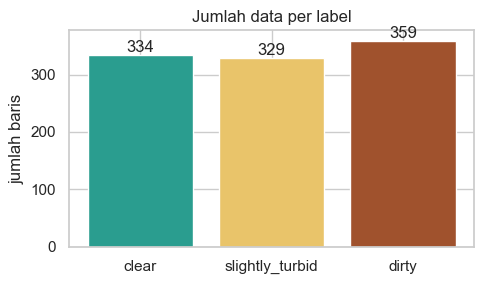

In [8]:
counts = df["label"].value_counts().reindex(LABELS)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=[COLORS[l] for l in LABELS])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, v, ha="center")
ax.set_ylabel("jumlah baris")
ax.set_title("Jumlah data per label")
fig.tight_layout()
fig.savefig("results/class_balance.png", dpi=150)
plt.show()

Jumlah data tiap label hampir sama, jadi akurasi masih bisa dipercaya buat dataset ini.

### 4.3 Nilai sensor dari waktu ke waktu

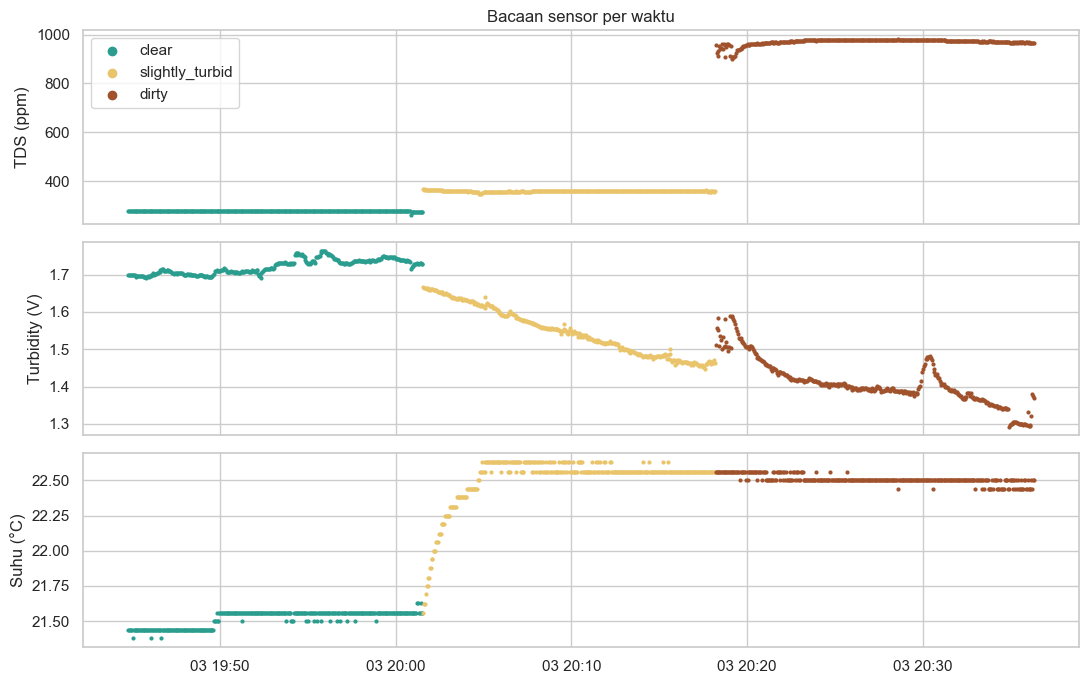

In [9]:
names = {"tds": "TDS (ppm)", "turb_v": "Turbidity (V)", "t_tank": "Suhu (°C)"}

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        part = df[df["label"] == label]
        ax.scatter(part["timestamp_wib"], part[col], s=4, color=COLORS[label], label=label)
    ax.set_ylabel(names[col])
axes[0].legend(loc="upper left", markerscale=3)
axes[0].set_title("Bacaan sensor per waktu")
fig.tight_layout()
fig.savefig("results/time_series.png", dpi=150)
plt.show()

- **TDS** datar dalam satu sesi, tapi beda jauh antar sesi (sekitar 276 / 358 / 970 ppm).
- **Tegangan turbidity** turun kalau airnya makin kotor, tapi masih naik-turun dalam satu sesi (lensa dan gelembung).
- **Suhu** beda sekitar 1 °C antar sesi gara-gara suhu ruangan, bukan karena kondisi airnya.
- Waktu rekaman aslinya sempat jeda (recording dimatikan dari dashboard waktu ngetes pompa, paling lama sekitar 7 menit).
  Timestamp sesudah jeda udah digeser di database biar rekamannya nyambung tiap 3 detik.

### 4.4 Sebaran nilai per label

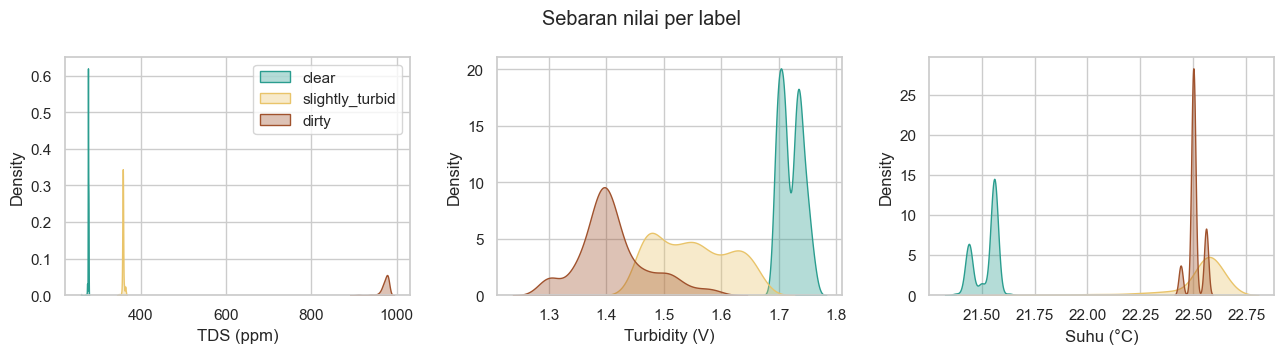

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        sns.kdeplot(df[df["label"] == label][col], ax=ax, fill=True, alpha=0.35,
                    color=COLORS[label], label=label, warn_singular=False)
    ax.set_xlabel(names[col])
axes[0].legend()
fig.suptitle("Sebaran nilai per label")
fig.tight_layout()
fig.savefig("results/distributions.png", dpi=150)
plt.show()

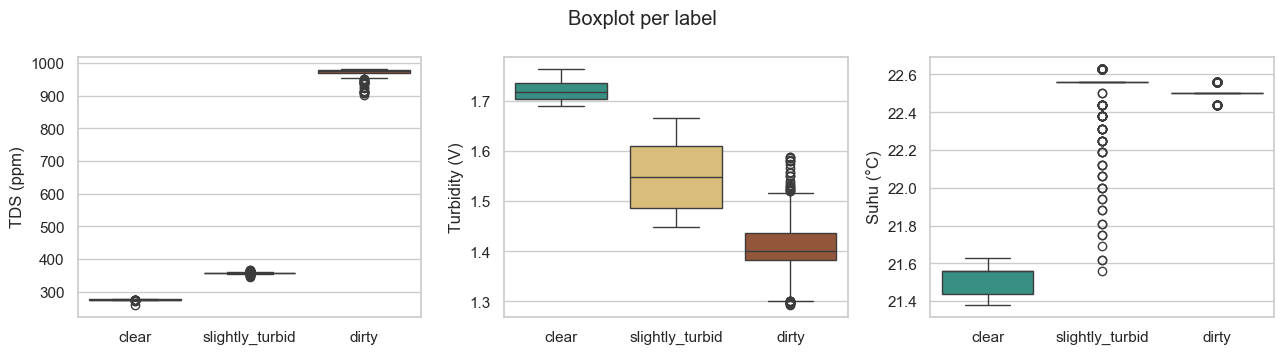

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(data=df, x="label", y=col, order=LABELS, palette=COLORS, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(names[col])
fig.suptitle("Boxplot per label")
fig.tight_layout()
fig.savefig("results/boxplots.png", dpi=150)
plt.show()

### 4.5 TDS vs turbidity

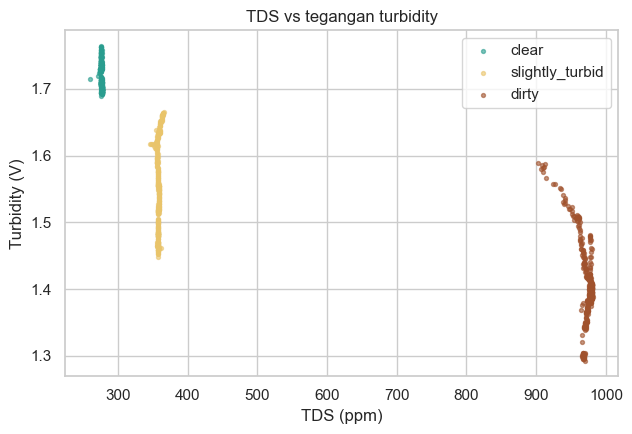

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label in LABELS:
    part = df[df["label"] == label]
    ax.scatter(part["tds"], part["turb_v"], s=8, alpha=0.6, color=COLORS[label], label=label)
ax.set_xlabel("TDS (ppm)")
ax.set_ylabel("Turbidity (V)")
ax.set_title("TDS vs tegangan turbidity")
ax.legend()
fig.tight_layout()
fig.savefig("results/scatter_tds_turb.png", dpi=150)
plt.show()

### 4.6 Korelasi

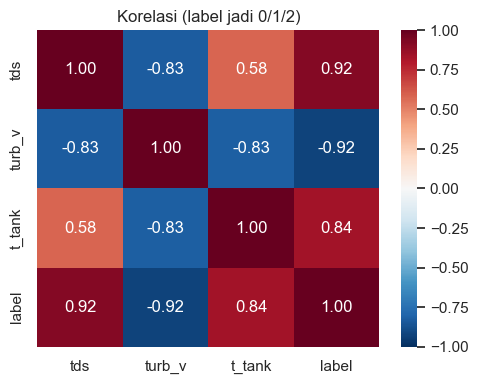

In [13]:
corr_df = df[SENSORS].copy()
corr_df["label"] = df["label"].cat.codes  # 0 clear, 1 slightly_turbid, 2 dirty

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi (label jadi 0/1/2)")
fig.tight_layout()
fig.savefig("results/correlation.png", dpi=150)
plt.show()

### 4.7 Kesimpulan EDA

1. TDS hampir sempurna misahin ketiga label, karena tiap level ditambah garam.
2. Tegangan turbidity ngikutin label (air bersih paling tinggi), tapi `slightly_turbid` dan `dirty` masih ada yang tumpang tindih.
3. Suhu beda antar sesi cuma karena suhu ruangan. Kalau dipakai, model malah belajar *kapan* direkam, bukan *seberapa kotor* airnya.
4. Tiap label itu 1 sesi rekaman, jadi baris yang berdekatan hampir sama. Ini ngaruh ke cara split data (bagian 6).

## 5. Pilih fitur

Kombinasi fitur yang dicoba:
- `tds + turb_v`: pilihan utama, dua sensor yang memang ngukur kondisi air.
- `tds` aja dan `turb_v` aja: buat lihat kontribusi masing-masing sensor.
- `tds + turb_v + t_tank`: buat ngecek suhu cuma nambah info sesi atau nggak.

Semua nilai ini ada di ESP32, jadi kombinasi mana pun bisa dipakai di sana.

In [14]:
FEATURE_SETS = {
    "tds + turb_v": ["tds", "turb_v"],
    "tds": ["tds"],
    "turb_v": ["turb_v"],
    "tds + turb_v + t_tank": ["tds", "turb_v", "t_tank"],
}
FEATURES = FEATURE_SETS["tds + turb_v"]

## 6. Split train/test

Kalau di-split random, baris yang hampir sama bakal masuk ke train dan test sekaligus, jadi skornya kelihatan lebih bagus
dari aslinya. Makanya **tiap label diambil 80% awal rekaman buat train dan 20% terakhir buat test**.

Buat cross-validation di data train, bagian train tiap label dipotong jadi 4 blok berurutan, terus `GroupKFold`
jaga supaya satu blok selalu ada di fold yang sama.

In [15]:
TEST_SIZE = 0.2
N_BLOCKS = 4

train_list, test_list = [], []
for label, group in df.groupby("label", observed=True):
    cut = int(len(group) * (1 - TEST_SIZE))
    part_train = group[:cut].copy()
    part_train["block"] = np.arange(len(part_train)) * N_BLOCKS // len(part_train)
    train_list.append(part_train)
    test_list.append(group[cut:])

train = pd.concat(train_list).reset_index(drop=True)
test = pd.concat(test_list).reset_index(drop=True)

print(pd.DataFrame({"train": train["label"].value_counts(), "test": test["label"].value_counts()}).reindex(LABELS))
print("\nTotal train:", len(train), "| test:", len(test))

                 train  test
label                       
clear              267    67
slightly_turbid    263    66
dirty              287    72

Total train: 817 | test: 205


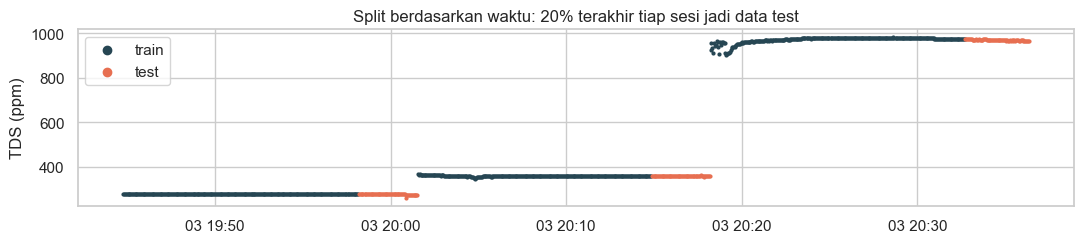

In [16]:
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.scatter(train["timestamp_wib"], train["tds"], s=4, color="#264653", label="train")
ax.scatter(test["timestamp_wib"], test["tds"], s=4, color="#e76f51", label="test")
ax.set_ylabel("TDS (ppm)")
ax.set_title("Split berdasarkan waktu: 20% terakhir tiap sesi jadi data test")
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig("results/split.png", dpi=150)
plt.show()

## 7. Training dan perbandingan model

Model yang dicoba (semua dari scikit-learn):

| Model | Kenapa dicoba |
|---|---|
| Decision Tree | aturan if-else simpel, gampang dipindah ke ESP32 |
| Random Forest | gabungan banyak tree, biasanya lebih stabil dari 1 tree |
| Gradient Boosting | model tabular yang kuat |
| k-Nearest Neighbours | bandingin sama data train yang paling mirip |
| Logistic Regression | baseline linear |
| SVM (RBF) | batas keputusan non-linear |
| Naive Bayes | baseline yang paling kecil |

k-NN, Logistic Regression, dan SVM sensitif sama skala data, jadi dikasih `StandardScaler` dulu.

In [17]:
def make_models():
    return {
        "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=42),
        "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
        "Naive Bayes": GaussianNB(),
    }

cv = GroupKFold(n_splits=N_BLOCKS)

### 7.1 Kedalaman decision tree

Kedalaman tree dipilih pakai cross-validation per blok, cuma dari data train.

 max_depth  cv_macro_f1       std
         1        0.557 7.327e-06
         2        0.999 2.171e-03
         3        0.999 2.171e-03
         4        0.999 2.171e-03
         5        0.999 2.171e-03
         6        0.999 2.171e-03


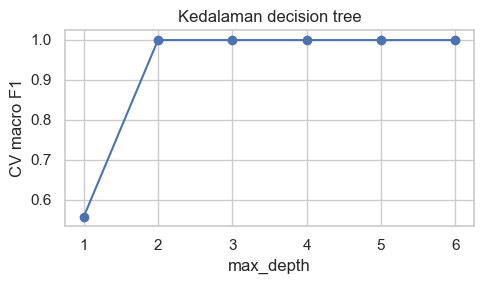

In [18]:
depth_rows = []
for depth in range(1, 7):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(tree, train[FEATURES], train["label"], groups=train["block"], cv=cv, scoring="f1_macro")
    depth_rows.append({"max_depth": depth, "cv_macro_f1": scores.mean(), "std": scores.std()})
depth_df = pd.DataFrame(depth_rows)
print(depth_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.errorbar(depth_df["max_depth"], depth_df["cv_macro_f1"], yerr=depth_df["std"], marker="o", capsize=3)
ax.set_xlabel("max_depth")
ax.set_ylabel("CV macro F1")
ax.set_title("Kedalaman decision tree")
fig.tight_layout()
fig.savefig("results/tree_depth.png", dpi=150)
plt.show()

### 7.2 Semua model pakai fitur utama (`tds + turb_v`)

In [19]:
def evaluate(features):
    rows = []
    fitted = {}
    for name, model in make_models().items():
        cv_f1 = cross_val_score(model, train[features], train["label"], groups=train["block"],
                                cv=cv, scoring="f1_macro").mean()
        model.fit(train[features], train["label"])
        pred = model.predict(test[features])
        rows.append({
            "model": name,
            "cv_macro_f1": cv_f1,
            "test_accuracy": accuracy_score(test["label"], pred),
            "test_macro_f1": f1_score(test["label"], pred, average="macro"),
        })
        fitted[name] = model
    table = pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
    return table, fitted

results, fitted = evaluate(FEATURES)
results.to_csv("results/model_comparison.csv", index=False)
results

,model,cv_macro_f1,test_accuracy,test_macro_f1
0,Decision Tree,0.999,1.0,1.0
1,Random Forest,1.000,1.0,1.0
2,Gradient Boosting,0.999,1.0,1.0
3,k-NN (k=5),1.000,1.0,1.0
4,Logistic Regression,0.960,1.0,1.0
5,SVM (RBF),0.999,1.0,1.0
6,Naive Bayes,1.000,1.0,1.0


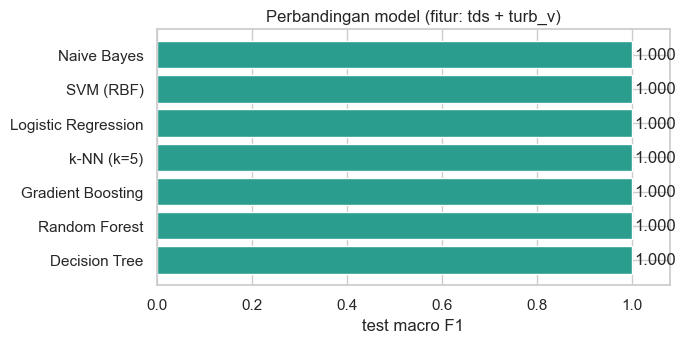

In [20]:
order = results.sort_values("test_macro_f1")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(order["model"], order["test_macro_f1"], color="#2a9d8f")
for y, v in enumerate(order["test_macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08)
ax.set_xlabel("test macro F1")
ax.set_title("Perbandingan model (fitur: tds + turb_v)")
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=150)
plt.show()

### 7.3 Perbandingan kombinasi fitur

Semua model ditrain ulang buat tiap kombinasi fitur, biar kelihatan kontribusi tiap sensor.

In [21]:
feature_table = pd.DataFrame()
for set_name, features in FEATURE_SETS.items():
    table, _ = evaluate(features)
    feature_table[set_name] = table.set_index("model")["test_macro_f1"]

feature_table.to_csv("results/feature_sets.csv")
feature_table.style.format("{:.3f}").background_gradient(cmap="Greens", vmin=0.3, vmax=1.0)

,tds + turb_v,tds,turb_v,tds + turb_v + t_tank
model,,,,
Decision Tree,1.000,1.000,0.695,1.000
Random Forest,1.000,1.000,0.695,1.000
Gradient Boosting,1.000,1.000,0.695,1.000
k-NN (k=5),1.000,1.000,0.695,1.000
Logistic Regression,1.000,1.000,0.573,1.000
SVM (RBF),1.000,1.000,0.695,1.000
Naive Bayes,1.000,1.000,0.573,1.000


### 7.4 Kenapa split-nya penting

Model yang sama dicoba pakai split **random** 80/20 buat perbandingan. Kalau skornya lebih tinggi,
itu cuma karena data yang hampir kembar bocor ke data test.

In [22]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    df[FEATURES], df["label"], test_size=TEST_SIZE, stratify=df["label"], random_state=42)

leak_rows = []
for name, model in make_models().items():
    model.fit(X_train_r, y_train_r)
    random_f1 = f1_score(y_test_r, model.predict(X_test_r), average="macro")
    time_f1 = results.set_index("model").loc[name, "test_macro_f1"]
    leak_rows.append({"model": name, "random_split_macro_f1": random_f1, "time_split_macro_f1": time_f1})
pd.DataFrame(leak_rows)

,model,random_split_macro_f1,time_split_macro_f1
0,Decision Tree,1.0,1.0
1,Random Forest,1.0,1.0
2,Gradient Boosting,1.0,1.0
3,k-NN (k=5),1.0,1.0
4,Logistic Regression,1.0,1.0
5,SVM (RBF),1.0,1.0
6,Naive Bayes,1.0,1.0


## 8. Evaluasi

### 8.1 Confusion matrix

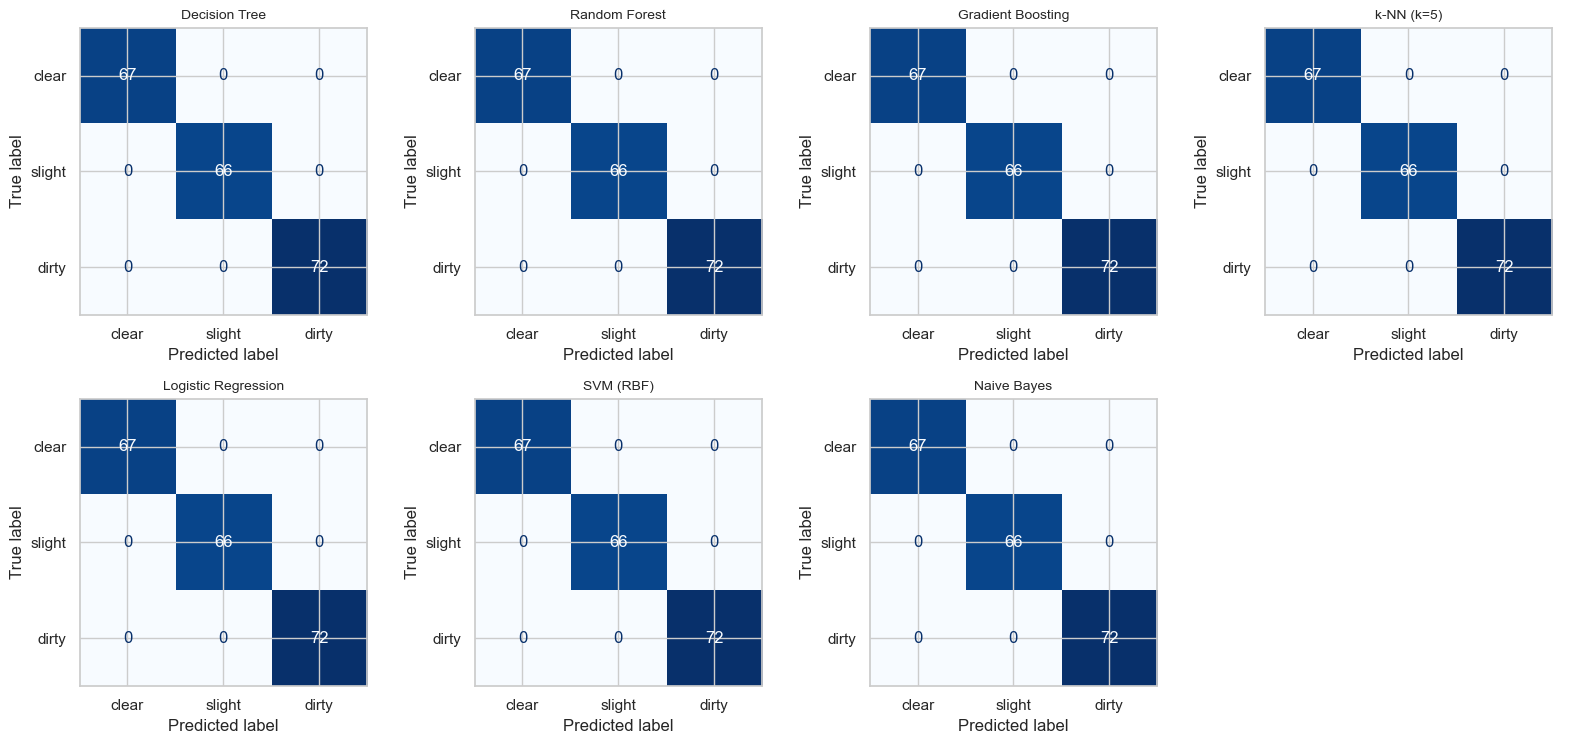

In [23]:
model_names = list(results["model"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7.6))
for ax, name in zip(axes.flat, model_names):
    pred = fitted[name].predict(test[FEATURES])
    cm = confusion_matrix(test["label"], pred, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=["clear", "slight", "dirty"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
axes.flat[-1].axis("off")  # 7 model, kotak ke-8 dikosongin
fig.tight_layout()
fig.savefig("results/confusion_matrices.png", dpi=150)
plt.show()

### 8.2 Classification report tiap model

In [24]:
for name in model_names:
    pred = fitted[name].predict(test[FEATURES])
    print("===", name, "===")
    print(classification_report(test["label"], pred, labels=LABELS, zero_division=0))

=== Decision Tree ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_turbid       1.00      1.00      1.00        66
          dirty       1.00      1.00      1.00        72

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205

=== Random Forest ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_turbid       1.00      1.00      1.00        66
          dirty       1.00      1.00      1.00        72

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205

=== Gradient Boosting ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_tu

### 8.3 Feature importance

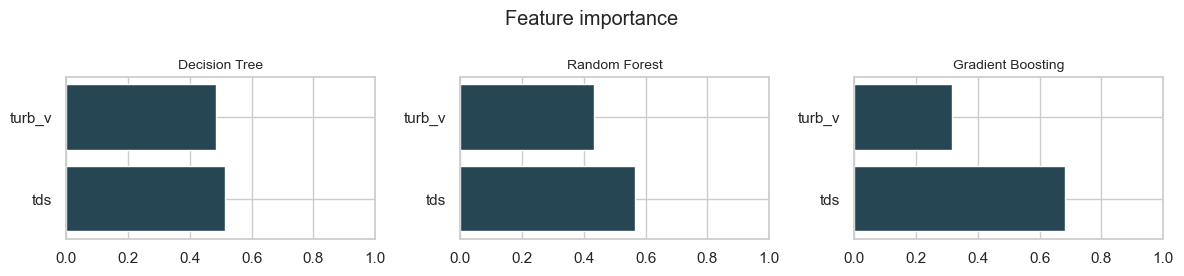

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, name in zip(axes, ["Decision Tree", "Random Forest", "Gradient Boosting"]):
    ax.barh(FEATURES, fitted[name].feature_importances_, color="#264653")
    ax.set_xlim(0, 1)
    ax.set_title(name, fontsize=10)
fig.suptitle("Feature importance")
fig.tight_layout()
fig.savefig("results/feature_importance.png", dpi=150)
plt.show()

### 8.4 Aturan decision tree

|--- tds <= 633.95
|   |--- turb_v <= 1.68
|   |   |--- class: slightly_turbid
|   |--- turb_v >  1.68
|   |   |--- class: clear
|--- tds >  633.95
|   |--- class: dirty



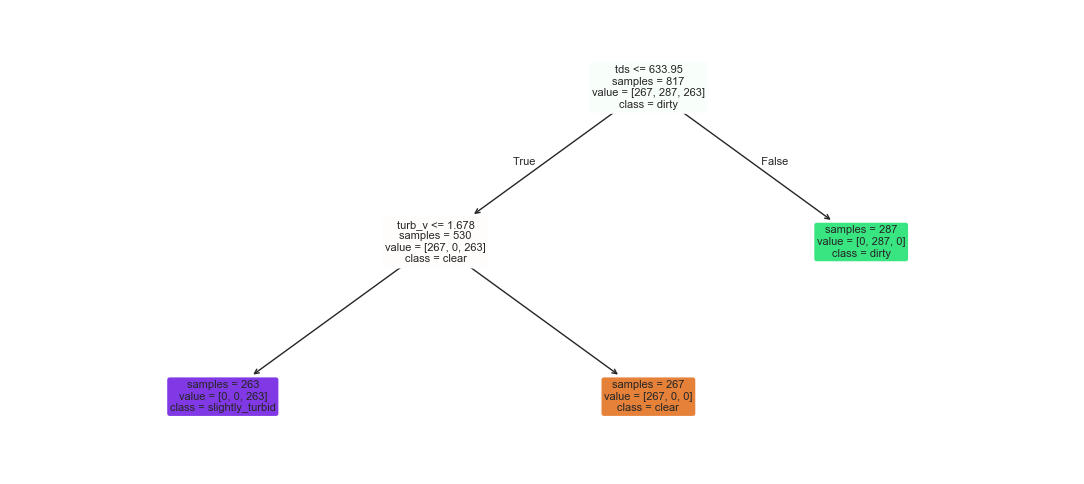

In [26]:
tree = fitted["Decision Tree"]
rules = export_text(tree, feature_names=FEATURES)
print(rules)
with open("results/decision_tree_rules.txt", "w") as f:
    f.write(rules)

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(tree, feature_names=FEATURES, class_names=list(tree.classes_), filled=True,
          rounded=True, impurity=False, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig("results/decision_tree.png", dpi=150)
plt.show()

### 8.5 Batas keputusan

Gimana tiap model ngebagi area TDS / turbidity. Titik-titiknya data test.

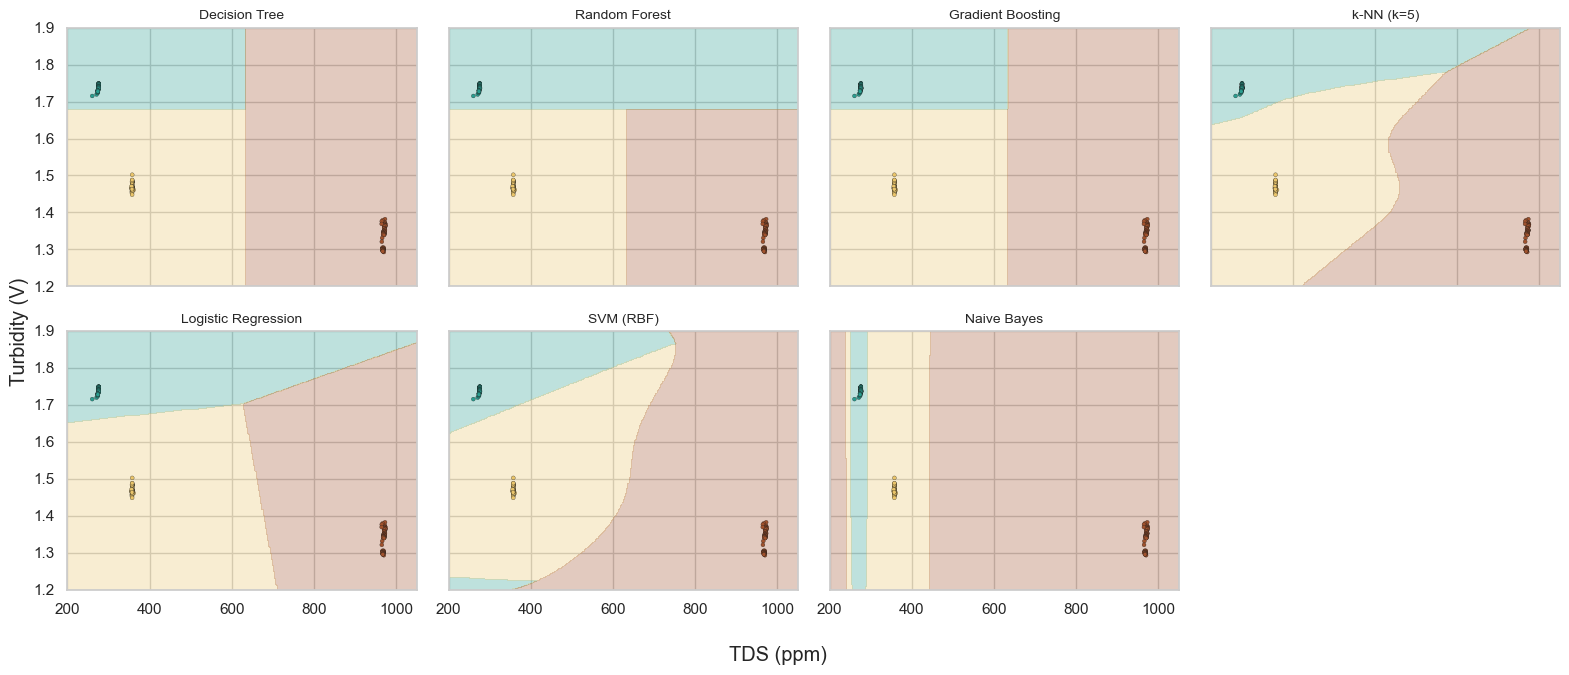

In [27]:
xx, yy = np.meshgrid(np.linspace(200, 1050, 300), np.linspace(1.2, 1.9, 300))
grid = pd.DataFrame({"tds": xx.ravel(), "turb_v": yy.ravel()})
label_to_num = {label: i for i, label in enumerate(LABELS)}
cmap = plt.matplotlib.colors.ListedColormap([COLORS[l] for l in LABELS])

fig, axes = plt.subplots(2, 4, figsize=(16, 6.8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, model_names):
    z = pd.Series(fitted[name].predict(grid)).map(label_to_num).values.reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap, alpha=0.3)
    ax.scatter(test["tds"], test["turb_v"], c=test["label"].map(label_to_num).astype(int), cmap=cmap,
               s=8, edgecolor="k", linewidth=0.2, vmin=0, vmax=2)
    ax.set_title(name, fontsize=10)
axes.flat[-1].axis("off")
fig.supxlabel("TDS (ppm)")
fig.supylabel("Turbidity (V)")
fig.tight_layout()
fig.savefig("results/decision_boundaries.png", dpi=150)
plt.show()

## 9. Model mana yang muat di ESP32

ESP32 cuma punya RAM sekitar 320 KB dan nggak bisa jalanin Python, jadi modelnya harus diubah jadi kode C.
Tabel ini kira-kira berapa banyak yang harus disimpan tiap model.

In [28]:
def model_size(name, model):
    if hasattr(model, "steps"):  # pipeline, ambil model terakhirnya
        model = model[-1]
    if name == "Decision Tree":
        return model.tree_.node_count, "node", "if-else, bisa langsung diexport"
    if name == "Random Forest":
        return sum(t.tree_.node_count for t in model.estimators_), "node", "100 tree if-else, header gede"
    if name == "Gradient Boosting":
        return sum(t.tree_.node_count for t in model.estimators_.ravel()), "node", "banyak tree kecil + penjumlahan"
    if name.startswith("k-NN"):
        return model.n_samples_fit_ * len(FEATURES), "nilai", "harus simpan semua data train"
    if name == "Logistic Regression":
        return model.coef_.size + model.intercept_.size, "angka", "cuma beberapa perkalian"
    if name.startswith("SVM"):
        return model.support_vectors_.size, "nilai", "harus simpan semua support vector"
    if name == "Naive Bayes":
        return model.theta_.size + model.var_.size, "angka", "mean dan varians per kelas"

size_rows = []
for name in model_names:
    size, unit, note = model_size(name, fitted[name])
    f1 = results.set_index("model").loc[name, "test_macro_f1"]
    size_rows.append({"model": name, "ukuran": size, "satuan": unit, "di ESP32": note, "test_macro_f1": f1})
esp = pd.DataFrame(size_rows)
esp.to_csv("results/esp32_size.csv", index=False)
esp

,model,ukuran,satuan,di ESP32,test_macro_f1
0,Decision Tree,5,node,"if-else, bisa langsung diexport",1.0
1,Random Forest,690,node,"100 tree if-else, header gede",1.0
2,Gradient Boosting,1490,node,banyak tree kecil + penjumlahan,1.0
3,k-NN (k=5),1634,nilai,harus simpan semua data train,1.0
4,Logistic Regression,9,angka,cuma beberapa perkalian,1.0
5,SVM (RBF),68,nilai,harus simpan semua support vector,1.0
6,Naive Bayes,12,angka,mean dan varians per kelas,1.0


## 10. Simpan model

Semua model disimpan biar bisa dipilih nanti. Yang dipasang di firmware itu Random Forest kecil
(10 tree, depth 3), diexport pakai:

```
python export_tree.py --csv data/iot_project_dataset_2026-11-04.csv
```

In [29]:
file_names = {
    "Decision Tree": "decision_tree",
    "Random Forest": "random_forest",
    "Gradient Boosting": "gradient_boosting",
    "k-NN (k=5)": "knn_k5",
    "Logistic Regression": "logistic_regression",
    "SVM (RBF)": "svm_rbf",
    "Naive Bayes": "naive_bayes",
}
for name, model in fitted.items():
    path = f"models/{file_names[name]}.joblib"
    joblib.dump({"model": model, "features": FEATURES, "labels": LABELS, "name": name}, path)
    print("disimpan:", path)

disimpan: models/decision_tree.joblib
disimpan: models/random_forest.joblib
disimpan: models/gradient_boosting.joblib
disimpan: models/knn_k5.joblib
disimpan: models/logistic_regression.joblib
disimpan: models/svm_rbf.joblib
disimpan: models/naive_bayes.joblib


## 11. AI vs rule-based (Assignment 2)

Di Assignment 2 ganti air diputusin pakai **rule R1**: health score < 60 lima kali berturut-turut.
Sekarang ESP32 juga punya **rule R4 (AI)**: model Random Forest bilang `dirty` (minimal 60% tree setuju)
lima kali berturut-turut. Dua-duanya dibandingin di data test yang sama.

Pertanyaannya: **air ini perlu diganti atau nggak?** Jawaban yang benar = label `dirty`.

Health score dihitung pakai rumus yang sama persis dengan firmware (`computeScore`):
TDS 50%, turbidity 37.5%, suhu 12.5%.

In [30]:
SCORE_THRESHOLD = 60
IN_A_ROW = 5          # LOW_READINGS_TO_ACT dan ML_DIRTY_READINGS di config.h
ML_MIN_CONFIDENCE = 0.6

def lin(v, good, bad):
    # 100 di nilai bagus, 0 di nilai jelek, linear di antaranya (sama kayak firmware)
    return 100 * (1 - np.clip((v - good) / (bad - good), 0, 1))

def health_score(row):
    t = row["t_tank"]
    temp = lin(t, 24, 20) if t < 24 else lin(t, 30, 34) if t > 30 else 100
    total = 0.5 * lin(row["tds"], 300, 700) + 0.375 * (100 - row["turb"]) + 0.125 * temp
    return round(total)

# Model yang sama dengan di ESP32: 10 tree, depth 3, 1 tree = 1 vote
esp_model = RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42)
esp_model.fit(train[FEATURES].values, train["label"])

def esp32_vote(model, X):
    votes = np.zeros((len(X), len(model.classes_)))
    for tree in model.estimators_:
        votes[np.arange(len(X)), tree.predict(X).astype(int)] += 1
    return model.classes_[votes.argmax(axis=1)], votes.max(axis=1) / len(model.estimators_)

cmp = test.sort_values("timestamp_wib").reset_index(drop=True).copy()
cmp["score"] = cmp.apply(health_score, axis=1)
cmp["ml"], cmp["ml_conf"] = esp32_vote(esp_model, cmp[FEATURES].values)

cmp["truth"] = cmp["label"] == "dirty"                                    # memang perlu ganti air
cmp["rule_based"] = cmp["score"] < SCORE_THRESHOLD                        # R1 (per pembacaan)
cmp["ai"] = (cmp["ml"] == "dirty") & (cmp["ml_conf"] >= ML_MIN_CONFIDENCE)  # R4 (per pembacaan)

cmp.groupby("label", observed=True)[["score", "ml_conf"]].describe().loc[LABELS].round(1)

score                                          ml_conf       \
                count  mean  std   min   25%   50%   75%   max   count mean   
label                                                                         
clear            67.0  91.5  0.6  90.0  91.0  92.0  92.0  92.0    67.0  1.0   
slightly_turbid  66.0  69.1  0.7  68.0  69.0  69.0  69.0  71.0    66.0  0.9   
dirty            72.0  17.1  2.0  14.0  15.0  18.0  19.0  20.0    72.0  1.0   

                                               
                 std  min  25%  50%  75%  max  
label                                          
clear            0.0  1.0  1.0  1.0  1.0  1.0  
slightly_turbid  0.0  0.9  0.9  0.9  0.9  1.0  
dirty            0.0  1.0  1.0  1.0  1.0  1.0

In [31]:
from sklearn.metrics import precision_score, recall_score

rows = []
for name, col in [("Rule-based (R1: score < 60)", "rule_based"), ("AI (R4: model bilang dirty)", "ai")]:
    rows.append({
        "sistem": name,
        "accuracy": accuracy_score(cmp["truth"], cmp[col]),
        "precision": precision_score(cmp["truth"], cmp[col], zero_division=0),
        "recall": recall_score(cmp["truth"], cmp[col], zero_division=0),
        "f1": f1_score(cmp["truth"], cmp[col], zero_division=0),
        "alarm palsu (pembacaan)": int((cmp[col] & ~cmp["truth"]).sum()),
        "kelewat (pembacaan)": int((~cmp[col] & cmp["truth"]).sum()),
    })
compare = pd.DataFrame(rows)
compare.to_csv("results/ai_vs_rule_based.csv", index=False)
compare.round(3)

,sistem,accuracy,precision,recall,f1,alarm palsu (pembacaan),kelewat (pembacaan)
0,Rule-based (R1: score < 60),1.0,1.0,1.0,1.0,0,0
1,AI (R4: model bilang dirty),1.0,1.0,1.0,1.0,0,0


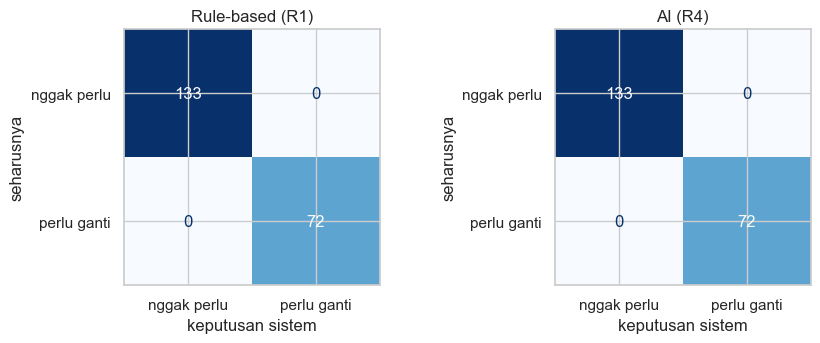

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, col) in zip(axes, [("Rule-based (R1)", "rule_based"), ("AI (R4)", "ai")]):
    cm = confusion_matrix(cmp["truth"], cmp[col], labels=[False, True])
    ConfusionMatrixDisplay(cm, display_labels=["nggak perlu", "perlu ganti"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("keputusan sistem")
    ax.set_ylabel("seharusnya")
fig.tight_layout()
fig.savefig("results/ai_vs_rule_based_cm.png", dpi=150)
plt.show()

### 11.1 Simulasi trigger pompa

Pompa baru nyala kalau kondisinya kejadian **5 kali berturut-turut**. Di sini data test diputar ulang per sesi label,
terus dihitung berapa kali tiap rule bakal nyalain pompa, dan setelah berapa pembacaan di sesi `dirty`.

In [33]:
def simulate(flags):
    # Sama kayak firmware: hitung berturut-turut, trigger di hitungan ke-5, lalu reset
    triggers, first, streak = 0, None, 0
    for i, flag in enumerate(flags):
        streak = streak + 1 if flag else 0
        if streak >= IN_A_ROW:
            triggers += 1
            first = i + 1 if first is None else first
            streak = 0
    return triggers, first

sim_rows = []
for label in LABELS:
    session = cmp[cmp["label"] == label]
    for name, col in [("Rule-based (R1)", "rule_based"), ("AI (R4)", "ai")]:
        n, first = simulate(session[col].tolist())
        sim_rows.append({"sesi": label, "sistem": name, "trigger": n,
                         "trigger pertama (pembacaan ke-)": first if first else "-"})
sim = pd.DataFrame(sim_rows)
sim.to_csv("results/trigger_simulation.csv", index=False)
sim

,sesi,sistem,trigger,trigger pertama (pembacaan ke-)
0,clear,Rule-based (R1),0,-
1,clear,AI (R4),0,-
2,slightly_turbid,Rule-based (R1),0,-
3,slightly_turbid,AI (R4),0,-
4,dirty,Rule-based (R1),14,5
5,dirty,AI (R4),14,5


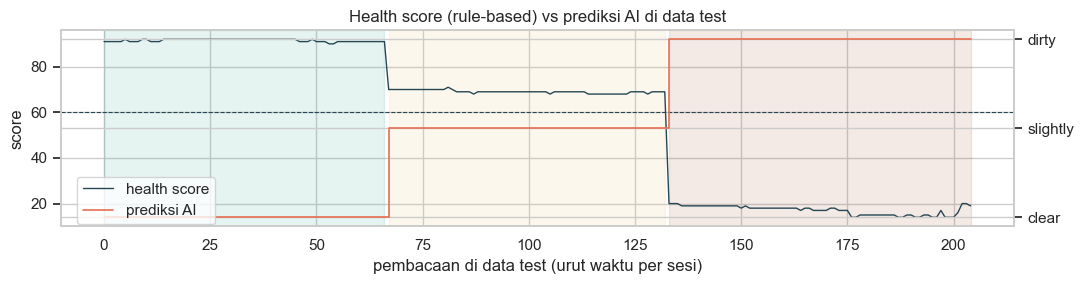

In [34]:
fig, ax = plt.subplots(figsize=(11, 3))
x = np.arange(len(cmp))
ax.plot(x, cmp["score"], color="#264653", lw=1, label="health score")
ax.axhline(SCORE_THRESHOLD, color="#264653", ls="--", lw=0.8)
ax2 = ax.twinx()
level = cmp["ml"].map({"clear": 0, "slightly_turbid": 1, "dirty": 2})
ax2.step(x, level, color="#e76f51", lw=1.2, where="post", label="prediksi AI")
ax2.set_yticks([0, 1, 2], ["clear", "slightly", "dirty"])
for label in LABELS:
    idx = np.where(cmp["label"] == label)[0]
    ax.axvspan(idx.min(), idx.max(), color=COLORS[label], alpha=0.12)
ax.set_xlabel("pembacaan di data test (urut waktu per sesi)")
ax.set_ylabel("score")
ax.set_title("Health score (rule-based) vs prediksi AI di data test")
fig.legend(loc="lower left", bbox_to_anchor=(0.07, 0.2))
fig.tight_layout()
fig.savefig("results/ai_vs_rule_based_timeline.png", dpi=150)
plt.show()

### 11.2 Uji ketahanan: tegangan turbidity turun

Waktu dites di alat, 5V-nya sempat drop dan `turb_v` di air bening turun dari ±1.75 V ke ±1.0 V
(serial log: `tds` 276, `turb_v` 1.02, `score` 54, `ml` slightly_turbid). Airnya sendiri nggak berubah.

Di sini data test digeser `turb_v`-nya (0 sampai -0.75 V), `turb` dan score dihitung ulang,
terus dilihat berapa banyak **alarm palsu** (bilang perlu ganti padahal bukan `dirty`).

In [35]:
TURB_V_CLEAR, TURB_V_SPAN = 1.75, 0.55   # sama dengan config.h

shift_rows = []
for shift in [0, -0.25, -0.5, -0.75]:
    noisy = cmp.copy()
    noisy["turb_v"] = noisy["turb_v"] + shift
    noisy["turb"] = np.clip((TURB_V_CLEAR - noisy["turb_v"]) / TURB_V_SPAN * 100, 0, 100)
    noisy["score"] = noisy.apply(health_score, axis=1)
    noisy["ml"], noisy["ml_conf"] = esp32_vote(esp_model, noisy[FEATURES].values)
    rule = noisy["score"] < SCORE_THRESHOLD
    ai = (noisy["ml"] == "dirty") & (noisy["ml_conf"] >= ML_MIN_CONFIDENCE)
    for name, flags in [("Rule-based (R1)", rule), ("AI (R4)", ai)]:
        not_dirty = ~noisy["truth"]
        shift_rows.append({
            "geser turb_v (V)": shift, "sistem": name,
            "alarm palsu clear": int((flags & (noisy["label"] == "clear")).sum()),
            "alarm palsu slightly": int((flags & (noisy["label"] == "slightly_turbid")).sum()),
            "alarm palsu (%)": round(100 * (flags & not_dirty).sum() / not_dirty.sum(), 1),
            "recall dirty": recall_score(noisy["truth"], flags, zero_division=0),
        })
shift_df = pd.DataFrame(shift_rows)
shift_df.to_csv("results/turbidity_shift_test.csv", index=False)
shift_df

,geser turb_v (V),sistem,alarm palsu clear,alarm palsu slightly,alarm palsu (%),recall dirty
0,0.00,Rule-based (R1),0,0,0.0,1.0
1,0.00,AI (R4),0,0,0.0,1.0
2,-0.25,Rule-based (R1),0,66,49.6,1.0
3,-0.25,AI (R4),0,0,0.0,1.0
4,-0.50,Rule-based (R1),67,66,100.0,1.0
5,-0.50,AI (R4),0,0,0.0,1.0
6,-0.75,Rule-based (R1),67,66,100.0,1.0
7,-0.75,AI (R4),0,0,0.0,1.0


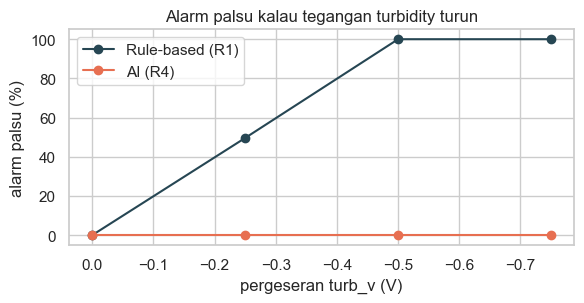

In [36]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, color in [("Rule-based (R1)", "#264653"), ("AI (R4)", "#e76f51")]:
    part = shift_df[shift_df["sistem"] == name]
    ax.plot(part["geser turb_v (V)"], part["alarm palsu (%)"], marker="o", color=color, label=name)
ax.set_xlabel("pergeseran turb_v (V)")
ax.set_ylabel("alarm palsu (%)")
ax.set_title("Alarm palsu kalau tegangan turbidity turun")
ax.invert_xaxis()
ax.legend()
fig.tight_layout()
fig.savefig("results/turbidity_shift_test.png", dpi=150)
plt.show()

## Kesimpulan

- **TDS paling berpengaruh** di dataset ini karena tiap label dibuat dengan nambah garam.
  Turbidity aja jauh kurang bisa misahin labelnya (bagian 7.3).
- **Tiap label cuma 1 sesi rekaman**, jadi data test masih dari sesi yang sama dengan train (cuma lebih belakang waktunya).
  Skor sempurna ini lebih karena tiga level garamnya beda jauh. Tes yang lebih adil itu pakai rekaman hari lain.
- **Suhu jangan dipakai**, soalnya cuma ngebedain sesi (suhu ruangan).
- **Yang dipakai di ESP32: Random Forest kecil (10 tree, depth 3).** Akurasi test 1.000 dengan 54 node, pakai TDS dan
  turbidity (importance 0.67 / 0.33). `export_tree.py` ngubah modelnya jadi C++ pakai micromlgen (1 vote per tree, hasilnya
  sama dengan scikit-learn di semua baris). Random Forest 100 tree dan Gradient Boosting nggak lebih bagus,
  k-NN dan SVM harus nyimpen banyak data. Model lain cuma buat pembanding.
- **AI vs rule-based (bagian 11):** di data test normal dua-duanya sempurna (accuracy, precision, recall, F1 = 1.0)
  dan sama-sama nyalain pompa setelah 5 pembacaan di sesi `dirty`. Bedanya kelihatan waktu tegangan turbidity turun:
  geser -0.25 V aja bikin rule-based kasih alarm palsu di ±50% pembacaan non-dirty (semua sesi `slightly_turbid`),
  dan di -0.5 V semuanya alarm palsu. AI tetap 0% karena keputusannya paling banyak dari TDS. Kebalikannya, kalau yang
  error sensor TDS, AI juga bakal ikut salah. Jadi di firmware dua rule-nya tetap jalan bareng (R1 dan R4).
- **AI juga kasih info lebih:** rule-based cuma bilang "ganti / nggak", AI bedain clear, slightly turbid, dan dirty,
  plus confidence (berapa persen tree yang setuju) yang tampil di dashboard dan Node-RED.